- Importing the neccesary libraries for ETL, regression decision trees , dataframes,plotting and more

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
df.head()
print("Shape:", df.shape)
print()
df.info()

Shape: (320, 7)

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   AdvertisingSpend_KES  320 non-null    int64
 1   StoreVisits           320 non-null    int64
 2   DiscountPercent       320 non-null    int64
 3   Region                320 non-null    str  
 4   CustomerSegment       320 non-null    str  
 5   ProductCategory       320 non-null    str  
 6   Sales_KES             320 non-null    int64
dtypes: int64(4), str(3)
memory usage: 24.1 KB


- The number or rows are 320, and number of columns are 7.

- The numeric columns are AdvertisingSpend_KES,storeVisits,DiscountPercent,Sales_KES

- The categorical variables are region,customersegment and product category

- One row represent a sale record.

- We are here to predict the sales it is our prediction target.

Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


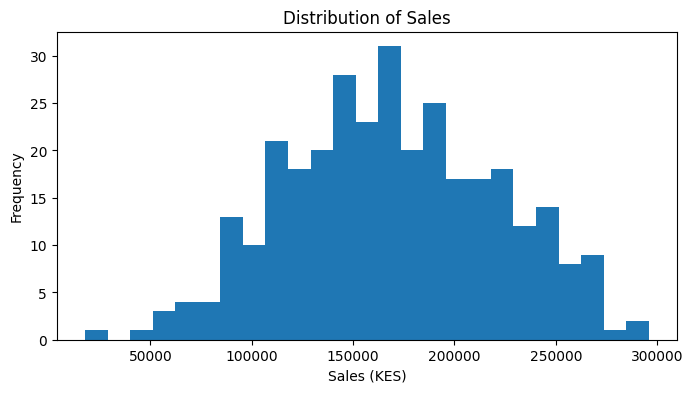

In [4]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
df["Sales_KES"].describe()
plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()



The target variable as we know is sales_KES, with a sales varying from 17805kes to 295825kes and has a pretty wide spread with median 168462kes and average sales to be 169252.44kes. 

- The extreme high values such as 290,000kes can show that they business might perform extremely well in certain regions  , or in certain segment or due to enough advertisement spent and that can help the decision makers spread this sucees throughout.Instead of assuming its an error in the dataset of sales

- Extreme low values such as around the 20,000ksh , can also let us know where the business needs improvemtn on the various segemtns, regions they are laacking in or can even be due to low advertisiment or low sales in a particular product due to people in that region not using that product, this will provide the business to implement or produce more product for that particular region.





Business question: Can available business characteristics be used to estimate sales?
• Analytical task: supervised regression.
• Target: Sales_KES.
• Features: AdvertisingSpend_KES, StoreVisits, DiscountPercent, Region, CustomerSegment,
ProductCategory.

Yes they can but will not give to a full extent give accurate  predictions, because we need to look at how the the the independent variables are correlated with one another like for example is advertising spend have a strong relationship with the amount of store visits .This will help us make a better model.

In [5]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.20,
random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


In [7]:
numeric_features = [
"AdvertisingSpend_KES",
"StoreVisits",
"DiscountPercent"
]
categorical_features = [
"Region",
"CustomerSegment",
"ProductCategory"
]

In [ ]:
numeric_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="most_frequent")),
("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
("num", numeric_pipeline, numeric_features),
("cat", categorical_pipeline, categorical_features)
])



 So when we call fit() on the pipeline, it will fit the preprocessing steps on the training data and then apply those transformations to the test data during prediction.

In [9]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")
mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)
mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

In [10]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
"Model": [name],
"MAE": [mean_absolute_error(y_true, y_pred)],
"RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
"R2": [r2_score(y_true, y_pred)]
})
mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")
pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


In [11]:
linear_model = Pipeline([
("preprocess", preprocessor),
("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
linear_results = evaluate_regression(
y_test, linear_pred, "Linear Regression"
)
linear_results



,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


far, the linear regression model has improved upon the baseline models in terms of MAE, RMSE, and R². This indicates that the linear regression model is providing better predictive performance compared to the mean and median baselines.

In [12]:
ridge_model = Pipeline([
("preprocess", preprocessor),
("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_results = evaluate_regression(
y_test, ridge_pred, "Ridge Regression"
)
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


In [14]:
tree_model = Pipeline([
("preprocess", preprocessor),
("model", DecisionTreeRegressor(
max_depth=4,
min_samples_leaf=8,
random_state=RANDOM_STATE
))
])
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
tree_results = evaluate_regression(
y_test, tree_pred, "Decision Tree")
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


In [15]:
comparison = pd.concat([
mean_results,
median_results,
linear_results,
ridge_results,
tree_results
], ignore_index=True)
comparison.sort_values("MAE")



,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


 The model with the lowest MAE and RMSE is the Decision Tree model, which also has the highest R² value among the models evaluated. Based on this table alone, I would choose the Decision Tree model as it appears to provide the best predictive performance on the test data. However, one table is not enough for a final conclusion because it does not account for other important factors such as model interpretability, potential overfitting, and performance on unseen data. Additionally, cross-validation results and further analysis of residuals and feature importance would provide a more comprehensive understanding of each model's strengths and weaknesses.

In [18]:
scoring = {
"MAE": "neg_mean_absolute_error",
"RMSE": "neg_root_mean_squared_error",
"R2": "r2"
}
models = {
"Linear Regression": linear_model,
"Ridge Regression": ridge_model,
"Decision Tree": tree_model
}
rows = []
for name, model in models.items():
    scores = cross_validate(
model, X_train, y_train,
cv=5,
scoring=scoring
)
rows.append({
"Model": name,
"CV_MAE": -scores["test_MAE"].mean(),
"CV_RMSE": -scores["test_RMSE"].mean(),
"CV_R2": scores["test_R2"].mean()})
cv_results = pd.DataFrame(rows)
cv_results



,Model,CV_MAE,CV_RMSE,CV_R2
0,Decision Tree,24498.468304,30608.682961,0.650627


The model that performs best on average can be determined by comparing the MAE, RMSE, and R2 values from the test results and cross-validation results. The model with the lowest MAE and RMSE and the highest R2 would be considered the best performer.

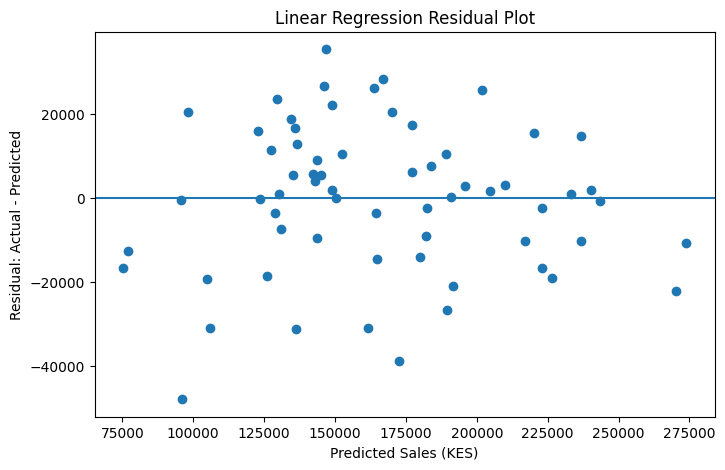

In [19]:
residuals = y_test - linear_pred
residual_df = pd.DataFrame({
"Actual": y_test.values,
"Predicted": linear_pred,
"Residual": residuals.values
})
residual_df.head()
plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()


 The residuals should be randomly scattered around zero, indicating that the model is appropriate for the data. If there is a pattern (e.g., a funnel shape), it may suggest heteroscedasticity or that the model is not capturing some aspect of the data. Large residuals (outliers) may indicate that the model is not performing well for certain observations, and further investigation may be needed to understand why these predictions are off.

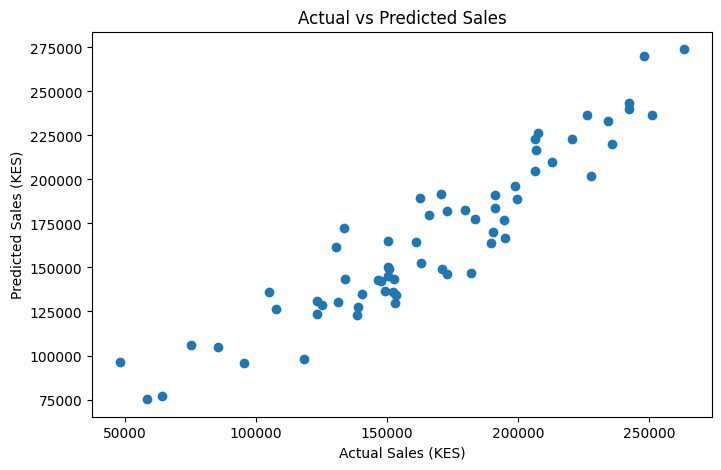

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()


 so the largest errors could be analyzed by looking at the residuals and identifying patterns. For example, you could group the residuals by region, customer segment, or product category to see if certain groups have consistently higher errors. Additionally, you might consider collecting more data on factors that could influence sales, such as marketing campaigns, competitor actions, or economic conditions, to improve the model's accuracy.

In [21]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()
error_analysis.sort_values(
"AbsoluteError", ascending=False
).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


In [ ]:
segment_errors = error_analysis.groupby(
"CustomerSegment"
).agg(
Observations=("AbsoluteError", "size"),
MAE=("AbsoluteError", "mean")
).reset_index()
segment_errors



,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


Highest MAE: Retail (about 15,561). SME is the lowest (about 10,481).
Sample sizes similar? Not quite. Retail has 27 test rows while SME and Corporate have 18–19. All are small, so these MAE values are noisy and could shift with a different split.
Why subgroup performance matters: An acceptable overall MAE can hide a group the model serves poorly. If the business makes Retail decisions using this model, Retail predictions are about 50% less accurate than SME predictions. That could lead to worse planning (stock, budgets) for that segment.

In [23]:
tree_train_pred = tree_model.predict(X_train)
print(
"Shallow Tree Training MAE:",
round(mean_absolute_error(y_train, tree_train_pred), 2)
)
print(
"Shallow Tree Test MAE:",
round(mean_absolute_error(y_test, tree_pred), 2)
)

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


In [28]:
eep_tree = Pipeline([
("preprocess", preprocessor),("model", DecisionTreeRegressor(
random_state=RANDOM_STATE
))
])
deep_tree = eep_tree
deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)
print(
"Deep Tree Training MAE:",
round(mean_absolute_error(y_train, deep_train_pred), 2)
)
print(
"Deep Tree Test MAE:",
round(mean_absolute_error(y_test, deep_test_pred), 2)
)



Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


A training MAE of 0 means the tree memorised every training row, including its random noise. It basically gave every row its own leaf. That memorisation does not carry over to new data, so its test MAE (26,798) is worse than the shallow tree’s (23,776). This is classic overfitting: a perfect training score shows how well a model remembers, not how well it predicts new data. Only the test or CV error tells you that.

Removing StoreVisits nearly destroys the model, with R² dropping from 0.87 to 0.24. It is the strongest predictor (correlation with sales = 0.77). Advertising (correlation 0.48) is the second most important. Because the two features are almost uncorrelated with each other, neither can “cover” for the other when it is removed.

The median baseline was the stronger baseline, but only just (MAE 39,147 vs 39,197 for the mean). Ridge Regression performed best, with a test MAE of about KES 13,714 and R² of 0.87, practically tied with Linear Regression. It clearly beat the baseline, cutting typical error by about 65%, and cross-validation confirmed this (CV MAE about 15,971 and CV R² about 0.85). In business terms, an MAE of about KES 14,000–16,000 means predicted sales are typically off by that amount, roughly 8–9% of an average sales value of about KES 169,000. Residuals were centred near zero with no strong pattern, though the model over-predicts some low-sales cases, especially those with few store visits. Performance differed by customer segment: Retail had the highest error (MAE about 15,561) and SME the lowest (about 10,481). The linear models showed no meaningful overfitting (train MAE about 15,100 vs test about 13,750), while the unrestricted decision tree overfit badly (train MAE 0, test MAE 26,798). I would not deploy the model immediately. It should first be validated on more recent, real-world data, Retail errors should be investigated, and stakeholders should agree on whether an error of about KES 15k is acceptable for their decisions.

- Small dataset: Only 320 rows, with a 64-row test set. Results, especially the subgroup MAEs, could change noticeably with a different split.
Likely synthetic/teaching data: Real business data would be messier, with missing values, errors, and stronger outliers, so real performance may be worse.

- Limited predictors: Important drivers such as seasonality, pricing, competitor activity, store size and stock levels are missing. This probably explains the remaining errors.

- Data drift: Customer behaviour, prices and the economy change over time, so a model trained on past data may become less accurate later.
Prediction is not causation: A positive advertising coefficient does not prove that spending more on ads will cause higher sales. It only shows an association in this data.